# Kaftet Restock - Advanced Analytics & Forecasting

## 1. Business Context and Objectives

**Kaftet (Kafe TETI)** is a self-service *honesty cafe*. An admin periodically restocks
snacks and drinks at **Indogrosir Yogyakarta**. Five receipts from 2026 were cleaned and
integrated in `kaftet_data_cleaning_integration (1).ipynb`, then explored in
`kaftet_restock_analysis.ipynb`.

This **third** notebook extends that work with analytics the earlier notebooks did not
cover: Pareto/ABC concentration, trip-to-trip diagnostics, a **forecasting-feasibility
assessment** with cautious baselines, price intelligence, hypothetical scenarios, an
inventory-planning *framework*, product segmentation, and a data-collection plan.

It is a **separate file**. It does not modify or overwrite the earlier notebooks or the
source workbook. It re-applies the same cleaning + standardisation logic so it runs
stand-alone.

> **The single most important caveat (repeated throughout):** this is **restock /
> purchasing** data - what the admin *bought*. It is **not** sales, consumption, or
> demand. We never infer that a product sells fast, is popular, or is profitable. A
> product missing from a trip does **not** mean zero demand or zero stock.

### Four metrics we keep strictly separate
| Metric | Definition | Source |
|--------|-----------|--------|
| **Line-item frequency** | number of receipt lines a product appears on | row count |
| **Purchase frequency** | number of distinct *trips* a product was bought on (<=5) | `receipt_date` nunique |
| **Recorded quantity** | sum of `qty` - **mixed packaging** (pieces vs cartons) | `qty` |
| **Expenditure** | money spent, normalised to rupiah | `line_spend_rp` |

## 2. Dataset Overview

We rebuild the cleaned, standardised item-level table using the same logic as the earlier
notebooks (header detection, type coercion, brand-name standardisation, *jastip* removal,
the one admin qty correction), then derive the analysis-only helper columns
(`receipt_date`, `unit_price_rp`, `line_spend_rp`, `brand`). Raw columns are preserved.

In [1]:
import re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", None); pd.set_option("display.width", 200)

SOURCE_FILE = Path("Struk_Indogrosir_restock_18_April_2026 (2).xlsx")
# NOTE: matplotlib only - seaborn is intentionally not required.

COLUMN_MAPPING = {"No":"line_no","Kode PLU":"plu_code","Nama Barang":"item_name","Qty":"qty",
 "Harga Satuan (Rp)":"unit_price","Diskon (Rp)":"discount","Total Sebelum Diskon (Rp)":"total_before_discount",
 "Total Akhir (Rp)":"total_after_discount","Total":"total_raw","Isi":"isi","Modal/pcs":"cost_per_pcs",
 "Jual/pcs":"sell_per_pcs","Jual Total":"sell_total","Untung":"profit","Untung/pcs":"profit_per_pcs",
 "sisa":"sisa","rusak":"rusak"}
NUMERIC_COLS = ["line_no","qty","unit_price","discount","total_before_discount","total_after_discount",
 "total_raw","isi","cost_per_pcs","sell_per_pcs","sell_total","profit","profit_per_pcs","sisa","rusak"]
NA_TOKENS = {"-","","nan","#div/0!","#value!","#ref!","#n/a","na","none"}

def find_header_row(df):
    for i in range(min(15,len(df))):
        row = " ".join(str(v).lower() for v in df.iloc[i].tolist())
        if "kode plu" in row and "nama barang" in row: return i
def classify_rows(df,h):
    out=[]
    for i in range(len(df)):
        if h is not None and i<h: out.append("metadata"); continue
        if i==h: out.append("header"); continue
        c0,c1=df.iat[i,0],df.iat[i,1]
        if pd.isna(c0) and pd.isna(c1): out.append("blank"); continue
        num=pd.to_numeric(pd.Series([c0]),errors="coerce").notna().iat[0]
        out.append("item" if (num and not pd.isna(c1)) else "summary")
    return pd.Series(out,index=df.index)
def to_number(x):
    if pd.isna(x): return np.nan
    s=str(x).strip()
    if s.lower() in NA_TOKENS: return np.nan
    if re.fullmatch(r"\d{1,3}(\.\d{3})+",s): s=s.replace(".","")
    s=s.replace(",","")
    try: return float(s)
    except ValueError: return np.nan
def extract_metadata(df):
    meta={"receipt_date_raw":np.nan,"receipt_time_raw":np.nan,"transaction_no":np.nan,"member":np.nan}
    top=" | ".join(str(v) for i in range(min(4,len(df))) for v in df.iloc[i].tolist() if not pd.isna(v))
    for k,pat in [("receipt_date_raw",r"Tanggal:\s*([0-9]{2}-[0-9]{2}-[0-9]{2,4})"),
                  ("receipt_time_raw",r"(\d{2}:\d{2}:\d{2})"),
                  ("transaction_no",r"No\.?\s*Transaksi:\s*([^\s|]+)"),
                  ("member",r"Member:\s*([^|]+?)\s*(?:\||$)")]:
        m=re.search(pat,top)
        if m: meta[k]=m.group(1).strip()
    return meta

In [2]:
raw_sheets = pd.read_excel(SOURCE_FILE, sheet_name=None, header=None)
header_rows = {n: find_header_row(d) for n,d in raw_sheets.items()}
row_kinds   = {n: classify_rows(d, header_rows[n]) for n,d in raw_sheets.items()}

def clean_sheet(name, df, h, kinds):
    items = df[kinds=="item"].copy(); items.columns=[str(c).strip() for c in df.iloc[h].tolist()]
    keep=[c for c in items.columns if c in COLUMN_MAPPING]; items=items[keep].rename(columns=COLUMN_MAPPING)
    items["source_row"]=items.index+1; items["source_sheet"]=name
    for col in ("item_name","plu_code"):
        if col in items: items[col]=items[col].astype(str).str.strip()
    if "plu_code" in items: items["plu_code"]=items["plu_code"].str.replace(r"\.0$","",regex=True).replace("nan",np.nan)
    for col in NUMERIC_COLS:
        if col in items: items[col]=items[col].map(to_number)
    for k,v in extract_metadata(df).items(): items[k]=v
    return items

cleaned = {n: clean_sheet(n, raw_sheets[n], header_rows[n], row_kinds[n]) for n in raw_sheets}
scale_flag = {n: ("thousands (decimals)" if (d["unit_price"].median()<1000) else "full rupiah")
              for n,d in cleaned.items()}
FINAL_COLUMNS = ["source_sheet","source_row","receipt_date_raw","receipt_time_raw","transaction_no",
 "member","line_no","plu_code","item_name","qty","unit_price","discount","total_before_discount",
 "total_after_discount","isi","cost_per_pcs","sell_per_pcs","sell_total","profit","profit_per_pcs",
 "sisa","rusak","price_scale_flag"]
parts=[]
for n,d in cleaned.items():
    t=d.copy(); t["price_scale_flag"]=scale_flag[n]
    for c in FINAL_COLUMNS:
        if c not in t: t[c]=np.nan
    parts.append(t[FINAL_COLUMNS])
integrated = pd.concat(parts, ignore_index=True)

# Admin standardisation (same as analysis notebook)
df = integrated.copy()
df.loc[(df["item_name"]=="ISOPLUS COCO 350ML") & (df["qty"]==12), "qty"] = 1  # one-off admin fix
rename_all = {
 "OISHI POPCRN COK 20G":"OISHI POPCORN COKELAT 20G","OISHI POPCRN KEJU20G":"OISHI POPCORN KEJU 20G",
 "OISHI PCRN CRMEL 20G":"OISHI POPCORN CARAMEL 20G","OISHI TCRN KEJU 20G":"OISHI POPCORN KEJU 20G",
 "OISHI PILLOW CHOCO12":"OISHI PILLOW CHOCO 12G","BC MKRONI LV.15/27G":"BONCABE MAKARONI LEVEL 15 27G",
 "BC CKR NAGA LV15 25G":"BONCABE CKR NAGA LEVEL 15 25G","MIKAKO S/AK MI GRG18":"MIKAKO SNACK MIE GORENG 18Gr",
 "MIKAKO SNAK MI GRG18":"MIKAKO SNACK MIE GORENG 18Gr","MIKAKO SNK RMPT LT18":"MIKAKO SNACK RUMPUT LAUT 18Gr",
 "TIC TAC SAPI PGG 14G":"TIC TAC SAPI PANGGANG 14Gr","TIC TAC AYAM BWNG 14":"TIC TAC AYAM BAWANG 14Gr",
 "TIC TAC PEDAS 14G":"TIC TAC PEDAS 14Gr","D/K TIC TAC MIX 14G":"TIC TAC MIX 14Gr",
 "MIE KRMEZ S&S AP 16G":"MIE KREMEZ SHAKE & SHOR AYAM PANGGANG 16Gr","MIE KREME S&S AP 16G":"MIE KREMEZ SHAKE & SHOR AYAM PANGGANG 16Gr",
 "M/KREMEZ S&S BLDO 16":"MIE KREMEZ SHAKE & SHOR BALADO 16Gr","TANGO WFLE CHOCOHZ21":"TANGO WAFFLE CHOCO HAZELNUT 21Gr",
 "TANGO WAF E CHOCOHZ21":"TANGO WAFFLE CHOCO HAZELNUT 21Gr","AOKA ROTI PGG KEJU15":"AOKA ROTI PGG KEJU65",
 "PUCUK/H TEH MLATI350":"PUCUK HARUM TEH MELATI 350ml","TEH PUCUK HARUM 6'S":"PUCUK HARUM TEH MELATI 350ml",
 "PUCUK/P TEH MELATI 350":"PUCUK HARUM TEH MELATI 350ml","PUCUK TH MLTI 350 ML":"PUCUK HARUM TEH MELATI 350ml",
 "ISOPLUS 2000 350ML":"ISOPLUS BTL 350ML","N/P MNM LIME 330 ML":"N/P MINUMAN LIME 330",
 "S/N SOSI MKN SP1525":"S/N SOSIS MKN SPI525","NABATI SIIP JG/BK20S":"NABATI SIIP JAGUNG BAKAR 4Gr",
 "NABATI SIIP KEJU 20S":"NABATI SIIP KEJU 4Gr","NABATI SIIP JG/BK 4G":"NABATI SIIP JAGUNG BAKAR 4Gr",
 "NABATI SIIP KEJU 4G":"NABATI SIIP KEJU 4Gr","NABATI RCHESE KEJU 5":"NABATI RICHEESE KEJU 5Gr",
 "NABATI RCHSE AHH 20S":"NABATI RICHEESE AHH 4Gr","NABATI SIIP CKLT 4G":"NABATI SIIP COKLAT 4Gr"}
df["item_name"] = df["item_name"].replace(rename_all).str.strip()
jastip = ["KIN B/YOG BLACK 45G","CMRY EAT MILK MATCHA","KZLER SS TOM YUM 60G",
          "GLADE PNY&BRY BLS 70","PRONAS SAUSGE CHIC65","INDF SMB CBK LIMAU5S"]
df = df[~df["item_name"].isin(jastip)].copy().reset_index(drop=True)

# analysis-only helper columns
df["receipt_date"] = pd.to_datetime(df["receipt_date_raw"], format="mixed", dayfirst=True, errors="coerce")
is_k = df["price_scale_flag"].str.startswith("thousands")
df["unit_price_rp"] = np.where(is_k, df["unit_price"]*1000, df["unit_price"])
df["total_after_rp"] = np.where(is_k, df["total_after_discount"]*1000, df["total_after_discount"])
df["line_spend_rp"] = df["qty"] * df["unit_price_rp"]
df["brand"] = df["item_name"].str.split().str[0].str.upper()

print("cleaned df:", df.shape, "| products:", df["item_name"].nunique(),
      "| trips:", df["receipt_date"].nunique())
TOTAL_SPEND = df["line_spend_rp"].sum()
print("total restock spend (Rp, qty*unit_price_rp):", f"{TOTAL_SPEND:,.0f}")

cleaned df: (167, 28) | products: 90 | trips: 5
total restock spend (Rp, qty*unit_price_rp): 4,520,600


In [3]:
# Shopping calendar: span and intervals between trips (key for forecasting feasibility).
dates = pd.Series(sorted(df["receipt_date"].dropna().unique()))
cal = pd.DataFrame({"trip_date": dates})
cal["gap_days_from_prev"] = cal["trip_date"].diff().dt.days
print("Observed shopping trips:", len(cal))
print("Span:", (dates.iloc[-1]-dates.iloc[0]).days, "days "
      f"({dates.iloc[0].date()} -> {dates.iloc[-1].date()})")
cal

Observed shopping trips: 5
Span: 153 days (2026-04-18 -> 2026-09-18)


,trip_date,gap_days_from_prev
0,2026-04-18,NaN
1,2026-06-23,66.0
2,2026-08-19,57.0
3,2026-09-04,16.0
4,2026-09-18,14.0


## 3. Data Quality Validation & Robustness

The analysis notebook already catalogued missing values, duplicates, date formats and
monetary scale. Here we focus on **robustness**: identifying the records whose anomalies
could *move the headline numbers*, and preparing a sensitivity flag. Anomalies are
**preserved**, never silently corrected.

In [4]:
# Flag the records most likely to distort aggregates:
#  (a) qty*unit_price_rp disagreeing with total_before_discount (rp) by >1%
#  (b) a product's price deviating hugely from its own median (possible scale/qty error)
dfx = df.copy()
tb_rp = np.where(dfx["price_scale_flag"].str.startswith("thousands"),
                 dfx["total_before_discount"]*1000, dfx["total_before_discount"])
dfx["tb_rp"] = tb_rp
dfx["exp_total"] = dfx["qty"] * dfx["unit_price_rp"]
dfx["consistency_rel_diff"] = (dfx["exp_total"] - dfx["tb_rp"]).abs() / pd.Series(tb_rp, index=dfx.index).replace(0, np.nan)

prod_med = dfx.groupby("item_name")["unit_price_rp"].transform("median")
dfx["price_vs_median_ratio"] = dfx["unit_price_rp"] / prod_med

flagged = dfx[(dfx["consistency_rel_diff"] > 0.01) |
              (dfx["price_vs_median_ratio"] < 0.2) | (dfx["price_vs_median_ratio"] > 5)]
print("Records flagged for manual review:", len(flagged))
flagged[["source_sheet","receipt_date_raw","item_name","qty","unit_price_rp",
         "tb_rp","total_after_discount","consistency_rel_diff","price_vs_median_ratio"]]

Records flagged for manual review: 2


,source_sheet,receipt_date_raw,item_name,qty,unit_price_rp,tb_rp,total_after_discount,consistency_rel_diff,price_vs_median_ratio
75,struk belanja (19-08-2026),19-08-2026,ISOPLUS COCO 350ML,1.0,2500.0,30000.0,30000.0,0.916667,0.086505
152,struk belanja (18-09-2026),18-09-26,PUCUK HARUM TEH MELATI 350ml,24.0,3150.0,75600.0,60.0,0.000000,0.044304


**Two records stand out** and are kept for the admin to confirm (not auto-fixed):

- **ISOPLUS COCO 350ML** (19-Aug): `unit_price` = 2,500 but `total_after` = 30,000 - a
  unit-price transcription slip.
- **PUCUK HARUM TEH MELATI 350ml** (18-Sep): `qty` = 24 with `unit_price` = 3,150 Rp,
  versus ~66,600-75,600 Rp on other trips. This looks like the quantity was entered as the
  pack size (`isi` = 24) and the price in the decimal/thousands scale - i.e. a combined
  scale + qty mix-up. We quantify its impact in the sensitivity analysis (section 8).

## 4. Descriptive Analytics - Concentration, Pareto & ABC

New here (beyond the earlier EDA): how **concentrated** Kaftet's spending is, an **ABC**
classification by expenditure, and the share of spend tied to the most *frequent* products.

> ABC uses **expenditure** (`line_spend_rp`), which is reasonably reliable after rupiah
> normalisation. It is a *purchasing-cost* classification, **not** a sales/importance
> ranking - a cheap item could still be vital to customers; we simply can't see that here.

In [5]:
# Product-level master table (every downstream section reuses this).
prod = (df.groupby("item_name")
          .agg(spend=("line_spend_rp","sum"), qty=("qty","sum"),
               records=("item_name","size"), trips=("receipt_date","nunique"),
               brand=("brand","first"))
          .sort_values("spend", ascending=False))
prod["spend_pct"] = prod["spend"] / prod["spend"].sum() * 100
prod["cum_spend_pct"] = prod["spend_pct"].cumsum()
prod["ABC"] = pd.cut(prod["cum_spend_pct"], bins=[-0.1, 80, 95, 100.1], labels=["A","B","C"])
print("Products:", len(prod))
prod.head(10)

Products: 90


,spend,qty,records,trips,brand,spend_pct,cum_spend_pct,ABC
item_name,,,,,,,,
PUCUK HARUM TEH MELATI 350ml,369000.0,28.0,4,4,PUCUK,8.162633,8.162633,A
MILKU SUSU STRO 200,300200.0,8.0,5,5,MILKU,6.640711,14.803345,A
SPRITE PET 390 ML,292100.0,5.0,5,5,SPRITE,6.461532,21.264876,A
N/P MINUMAN LIME 330,238000.0,5.0,3,3,N/P,5.264788,26.529664,A
ISOPLUS BTL 350ML,207800.0,7.0,5,5,ISOPLUS,4.596735,31.126399,A
COCA COLA PET 390 ML,175000.0,3.0,3,3,COCA,3.871168,34.997567,A
MILKU SUSU CKLT 200,173300.0,5.0,4,4,MILKU,3.833562,38.831129,A
VIT AIR MINERAL 550,158700.0,5.0,3,3,VIT,3.510596,42.341725,A
FANTA STRW PET 390ML,117100.0,2.0,2,2,FANTA,2.590364,44.932089,A


In [6]:
# ABC summary: few 'A' products carry most of the spend.
abc_summary = (prod.groupby("ABC")
                 .agg(n_products=("spend","size"), total_spend=("spend","sum"))
                 .assign(pct_of_products=lambda x: (x["n_products"]/len(prod)*100).round(1),
                         pct_of_spend=lambda x: (x["total_spend"]/prod["spend"].sum()*100).round(1)))
abc_summary

,n_products,total_spend,pct_of_products,pct_of_spend
ABC,,,,
A,34,3582500.0,37.8,79.2
B,30,710300.0,33.3,15.7
C,26,227800.0,28.9,5.0


In [7]:
# Pareto: how many SKUs make up 80% of spend?
n80 = int((prod["cum_spend_pct"] <= 80).sum()) + 1
print(f"{n80} of {len(prod)} products ({n80/len(prod)*100:.0f}% of SKUs) account for ~80% of spend.")
# Share of spend from the 10 most FREQUENT products (line-item frequency).
top_freq10 = prod.sort_values("records", ascending=False).head(10)
print("Top-10 most-frequent products' share of total spend:",
      f"{top_freq10['spend'].sum()/prod['spend'].sum()*100:.1f}%")

35 of 90 products (39% of SKUs) account for ~80% of spend.
Top-10 most-frequent products' share of total spend: 46.3%


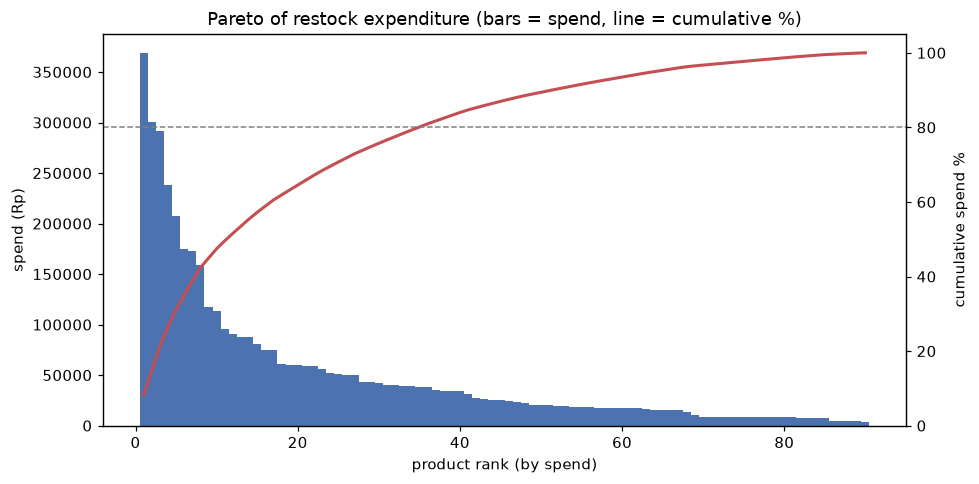

In [8]:
# Pareto chart: cumulative spend vs product rank.
fig, ax = plt.subplots(figsize=(9,4.5))
rank = np.arange(1, len(prod)+1)
ax.bar(rank, prod["spend"].values, color="#4C72B0", width=1.0, label="spend per product")
ax2 = ax.twinx()
ax2.plot(rank, prod["cum_spend_pct"].values, color="#C44E52", lw=2, label="cumulative %")
ax2.axhline(80, color="grey", ls="--", lw=1)
ax2.set_ylim(0,105); ax2.set_ylabel("cumulative spend %")
ax.set_xlabel("product rank (by spend)"); ax.set_ylabel("spend (Rp)")
ax.set_title("Pareto of restock expenditure (bars = spend, line = cumulative %)")
plt.tight_layout(); plt.show()

In [9]:
# Line-item frequency vs recorded quantity vs purchase frequency - these are DIFFERENT.
compare = pd.DataFrame({
    "most_line_item_freq": prod.sort_values("records", ascending=False).head(8)["records"],
}).join(
    prod.sort_values("qty", ascending=False).head(8)["qty"].rename("most_recorded_qty"),
    how="outer")
print("Note how the 'most frequent' and 'highest quantity' lists barely overlap:")
display(prod.sort_values("records", ascending=False).head(8)[["records","trips","qty","spend"]])
display(prod.sort_values("qty", ascending=False).head(8)[["qty","records","trips","spend"]])

Note how the 'most frequent' and 'highest quantity' lists barely overlap:


,records,trips,qty,spend
item_name,,,,
MILKU SUSU STRO 200,5,5,8.0,300200.0
SPRITE PET 390 ML,5,5,5.0,292100.0
ISOPLUS BTL 350ML,5,5,7.0,207800.0
PUCUK HARUM TEH MELATI 350ml,4,4,28.0,369000.0
MILKU SUSU CKLT 200,4,4,5.0,173300.0
ISOPLUS COCO 350ML,4,4,4.0,90300.0
OISHI POPCORN KEJU 20G,4,4,5.0,87500.0
VIT AIR MINERAL 550,3,3,5.0,158700.0


,qty,records,trips,spend
item_name,,,,
AOKA ROTI PG BL/STR,33.0,3,3,60000.0
PUCUK HARUM TEH MELATI 350ml,28.0,4,4,369000.0
AOKA ROTI PGG CKLT65,28.0,3,3,52000.0
AOKA ROTI SUSU VNLA,27.0,3,3,50000.0
AOKA ROTI PGG KEJU65,27.0,3,3,50000.0
AOKA ROTI DURIAN,22.0,3,3,42000.0
AOKA NANAS PCK65,14.0,2,2,26000.0
AOKA KLAPA PNDAN 65G,14.0,2,2,25200.0


In [10]:
# Assortment change across trips: how many products are new vs repeated each trip.
by_trip_items = {d: set(g["item_name"]) for d, g in df.groupby("receipt_date")}
trip_dates = sorted(by_trip_items)
seen = set(); rows = []
for d in trip_dates:
    items = by_trip_items[d]
    new = items - seen
    rows.append({"trip": d.date(), "distinct_items": len(items),
                 "new_items": len(new), "repeated_from_before": len(items & seen)})
    seen |= items
assortment = pd.DataFrame(rows)
assortment

,trip,distinct_items,new_items,repeated_from_before
0,2026-04-18,36,36,0
1,2026-06-23,22,10,12
2,2026-08-19,40,23,17
3,2026-09-04,29,13,16
4,2026-09-18,40,8,32


## 5. Diagnostic Analytics - Why do trips differ?

Trip expenditure ranges widely (smallest ~585k on 23-Jun, largest ~1.32m on 18-Sep). We
decompose the difference into **assortment** (how many distinct items), **quantity** (units
bought) and **price** (average normalised unit price). We describe *associations*, not
causes: with only five trips we cannot prove why spend changed.

In [11]:
# Per-trip drivers side by side.
trip = (df.groupby("receipt_date")
          .agg(records=("item_name","size"), distinct_items=("item_name","nunique"),
               units=("qty","sum"), spend=("line_spend_rp","sum"),
               avg_unit_price=("unit_price_rp","mean"))
          .round(0))
trip["spend_per_item"] = (trip["spend"]/trip["distinct_items"]).round(0)
trip

,records,distinct_items,units,spend,avg_unit_price,spend_per_item
receipt_date,,,,,,
2026-04-18,36,36,54.0,768000.0,19347.0,21333.0
2026-06-23,22,22,42.0,585400.0,23486.0,26609.0
2026-08-19,40,40,79.0,902500.0,19865.0,22562.0
2026-09-04,29,29,75.0,944000.0,19131.0,32552.0
2026-09-18,40,40,146.0,1320700.0,21571.0,33018.0


In [12]:
# Correlation of trip spend with its possible drivers (DESCRIPTIVE only, n=5 trips!).
corr = trip[["spend","records","distinct_items","units","avg_unit_price"]].corr()["spend"].round(2)
print("Correlation of trip spend with each driver (n=5 trips - indicative, NOT causal):")
print(corr)
print("\nReading: spend tracks units/records/assortment closely; with only 5 points this")
print("is an observed association, not evidence of cause.")

Correlation of trip spend with each driver (n=5 trips - indicative, NOT causal):
spend             1.00
records           0.69
distinct_items    0.69
units             0.98
avg_unit_price   -0.20
Name: spend, dtype: float64

Reading: spend tracks units/records/assortment closely; with only 5 points this
is an observed association, not evidence of cause.


In [13]:
# Which PRODUCTS drive the spend gap between the cheapest and most expensive trip?
lo_date = trip["spend"].idxmin(); hi_date = trip["spend"].idxmax()
lo = df[df["receipt_date"]==lo_date].groupby("item_name")["line_spend_rp"].sum()
hi = df[df["receipt_date"]==hi_date].groupby("item_name")["line_spend_rp"].sum()
delta = (hi.reindex(hi.index.union(lo.index), fill_value=0)
         - lo.reindex(hi.index.union(lo.index), fill_value=0)).sort_values(ascending=False)
print(f"Biggest spend increases from {lo_date.date()} (low) to {hi_date.date()} (high):")
display(delta.head(10).to_frame("spend_delta_rp"))
print("Biggest decreases:")
display(delta.tail(5).to_frame("spend_delta_rp"))

Biggest spend increases from 2026-06-23 (low) to 2026-09-18 (high):


,spend_delta_rp
item_name,
YUPI GUMMY PIZZA 23G,96000.0
N/P MINUMAN LIME 330,95200.0
FANTA STRW PET 390ML,60600.0
G/T CHOCHP D/CHO26.5,43000.0
MIE KREMEZ SHAKE & SHOR BALADO 16Gr,40200.0
GOLDA CAPPUCCINO 200,37300.0
GOLDA COFF.DOLCE 200,37300.0
AOKA ROTI PG BL/STR,36000.0
OISHI POPCORN CARAMEL 20G,35000.0


Biggest decreases:


,spend_delta_rp
item_name,
TOS TOS TRTCS KBQ20,-17100.0
OISHI POPCORN COKELAT 20G,-17500.0
CHITATO SAPI PGG 15G,-18900.0
MIE KREMEZ SHAKE & SHOR AYAM PANGGANG 16Gr,-20100.0
COCA COLA PET 390 ML,-62000.0


In [14]:
# Repeat vs one-off products (purchase frequency = # trips).
freq_dist = prod["trips"].value_counts().sort_index().rename_axis("trips_present").to_frame("n_products")
print("How many products appear on N trips:")
display(freq_dist)
print("Products bought on ALL 5 trips (the only truly recurring staples):")
display(prod[prod["trips"]==5][["spend","qty","records"]])
print(f"One-off products (single trip): {(prod['trips']==1).sum()} of {len(prod)}")

How many products appear on N trips:


,n_products
trips_present,
1,46
2,21
3,16
4,4
5,3


Products bought on ALL 5 trips (the only truly recurring staples):


,spend,qty,records
item_name,,,
MILKU SUSU STRO 200,300200.0,8.0,5
SPRITE PET 390 ML,292100.0,5.0,5
ISOPLUS BTL 350ML,207800.0,7.0,5


One-off products (single trip): 46 of 90


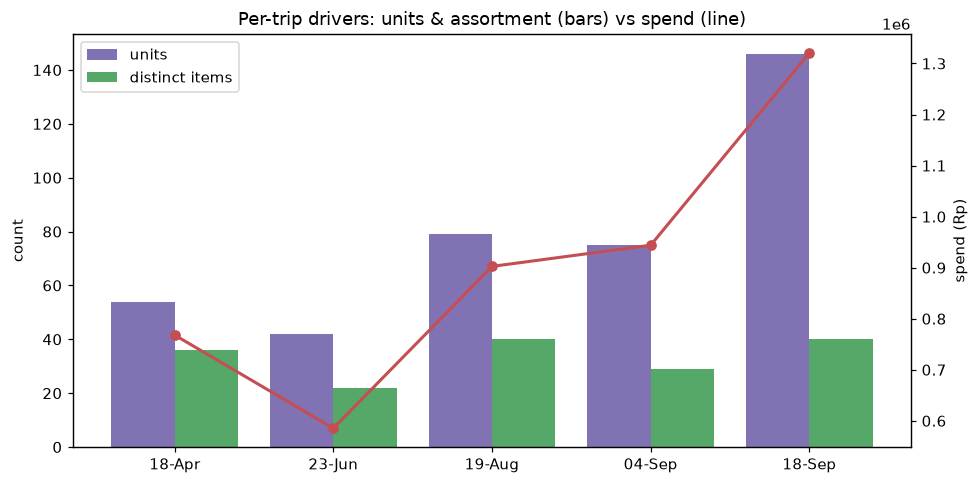

In [15]:
# Diagnostic viz: stacked drivers per trip (units & distinct items) + spend line.
fig, ax = plt.subplots(figsize=(9,4.5))
x = np.arange(len(trip)); labels=[d.strftime('%d-%b') for d in trip.index]
ax.bar(x-0.2, trip["units"], width=0.4, label="units", color="#8172B3")
ax.bar(x+0.2, trip["distinct_items"], width=0.4, label="distinct items", color="#55A868")
ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylabel("count"); ax.legend(loc="upper left")
ax2=ax.twinx(); ax2.plot(x, trip["spend"], color="#C44E52", marker="o", lw=2, label="spend")
ax2.set_ylabel("spend (Rp)")
ax.set_title("Per-trip drivers: units & assortment (bars) vs spend (line)")
plt.tight_layout(); plt.show()

## 6. Price & Expenditure Analysis (Price Intelligence)

We compare **normalised** prices (`unit_price_rp`) for the *same standardised product*
across trips. Comparisons are only meaningful for identical product + packaging; where a
record looks like a scale/packaging error (section 3) we note it rather than trust it.

In [16]:
# Price history per product that appears on >=2 trips.
price_hist = (df.groupby(["item_name","receipt_date"])["unit_price_rp"].mean()
                .reset_index())
pstats = (price_hist.groupby("item_name")["unit_price_rp"]
            .agg(n_obs="count", min="min", max="max", mean="mean", std="std"))
pstats = pstats[pstats["n_obs"]>=2].copy()
pstats["range"] = pstats["max"] - pstats["min"]
pstats["cv_pct"] = (pstats["std"]/pstats["mean"]*100).round(1)
print("Largest observed price ranges (top of list includes likely data anomalies):")
pstats.sort_values("range", ascending=False).head(10)

Largest observed price ranges (top of list includes likely data anomalies):


,n_obs,min,max,mean,std,range,cv_pct
item_name,,,,,,,
PUCUK HARUM TEH MELATI 350ml,4,3150.0,75600.0,55237.500000,34983.219191,72450.0,63.3
ISOPLUS COCO 350ML,4,2500.0,30000.0,22575.000000,13393.375228,27500.0,59.3
MILKU SUSU STRO 200,5,34500.0,42300.0,36180.000000,3422.279942,7800.0,9.5
COCA COLA PET 390 ML,3,56500.0,62000.0,58333.333333,3175.426481,5500.0,5.4
SPRITE PET 390 ML,5,56500.0,62000.0,58420.000000,2675.256997,5500.0,4.6
FANTA STRW PET 390ML,2,56500.0,60600.0,58550.000000,2899.137803,4100.0,5.0
NABATI RICHEESE KEJU 5Gr,2,8500.0,10400.0,9450.000000,1343.502884,1900.0,14.2
VIT AIR MINERAL 550,3,31000.0,32400.0,31766.666667,709.459888,1400.0,2.2
ISOPLUS BTL 350ML,5,28900.0,30000.0,29560.000000,602.494813,1100.0,2.0


In [17]:
# Largest observed price INCREASES / DECREASES (first vs last observation per product).
def first_last(g):
    g = g.sort_values("receipt_date")
    return pd.Series({"first_price": g["unit_price_rp"].iloc[0],
                      "last_price": g["unit_price_rp"].iloc[-1]})
fl = price_hist.groupby("item_name").apply(first_last)
fl = fl[fl.index.isin(pstats.index)].copy()
fl["pct_change"] = ((fl["last_price"]-fl["first_price"])/fl["first_price"]*100).round(1)
print("Biggest price INCREASES (first->last obs):")
display(fl.sort_values("pct_change", ascending=False).head(6))
print("Biggest price DECREASES (watch for anomalies like PUCUK HARUM):")
display(fl.sort_values("pct_change").head(6))

Biggest price INCREASES (first->last obs):


,first_price,last_price,pct_change
item_name,,,
NABATI RICHEESE KEJU 5Gr,8500.0,10400.0,22.4
FANTA STRW PET 390ML,56500.0,60600.0,7.3
SPRITE PET 390 ML,56500.0,60600.0,7.3
TANGO WAFFLE CHOCO HAZELNUT 21Gr,20000.0,21000.0,5.0
NABATI SIIP KEJU 4Gr,8500.0,8900.0,4.7
NABATI SIIP JAGUNG BAKAR 4Gr,8500.0,8900.0,4.7


Biggest price DECREASES (watch for anomalies like PUCUK HARUM):


,first_price,last_price,pct_change
item_name,,,
PUCUK HARUM TEH MELATI 350ml,66600.0,3150.0,-95.3
AOKA NANAS PCK65,2000.0,1800.0,-10.0
AOKA ROTI PGG KEJU65,2000.0,1800.0,-10.0
AOKA ROTI DURIAN,2000.0,1800.0,-10.0
AOKA ROTI SUSU VNLA,2000.0,1800.0,-10.0
AOKA ROTI PGG CKLT65,2000.0,1800.0,-10.0


In [18]:
# Stable-price products (same observed price on every trip they appear) - safe to budget.
stable = pstats[pstats["range"]==0]
print(f"Products with a perfectly stable observed price (>=2 trips): {len(stable)}")
display(stable.head(10)[["n_obs","mean"]])

Products with a perfectly stable observed price (>=2 trips): 24


,n_obs,mean
item_name,,
AOKA KLAPA PNDAN 65G,2,1800.0
BONCABE CKR NAGA LEVEL 15 25G,2,17200.0
BONCABE MAKARONI LEVEL 15 27G,3,17200.0
DILAN CHOCO CARAML23,2,20000.0
GARUDA PILUS RMP LT7,2,8600.0
GOLDA CAPPUCCINO 200,2,37300.0
GOLDA COFF.DOLCE 200,2,37300.0
MIE KREMEZ SHAKE & SHOR AYAM PANGGANG 16Gr,3,20100.0
MIE KREMEZ SHAKE & SHOR BALADO 16Gr,2,20100.0


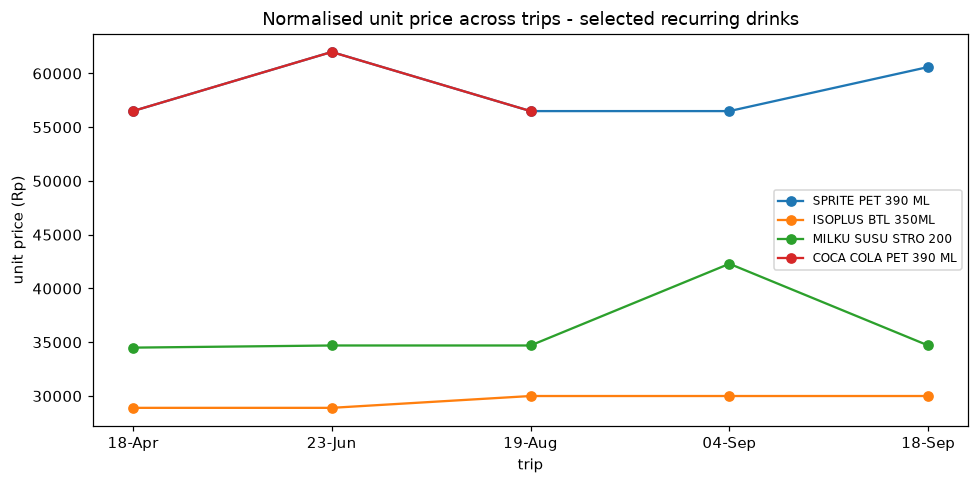

In [19]:
# Price trajectories for a few clearly-comparable recurring drinks (exclude anomalies).
watch = ["SPRITE PET 390 ML","ISOPLUS BTL 350ML","MILKU SUSU STRO 200","COCA COLA PET 390 ML"]
fig, ax = plt.subplots(figsize=(9,4.5))
for name in watch:
    s = price_hist[price_hist["item_name"]==name].sort_values("receipt_date")
    if len(s): ax.plot(s["receipt_date"].dt.strftime('%d-%b'), s["unit_price_rp"], marker="o", label=name[:20])
ax.set_title("Normalised unit price across trips - selected recurring drinks")
ax.set_ylabel("unit price (Rp)"); ax.set_xlabel("trip"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Forecasting Feasibility & Baseline Models

### 7.1 Feasibility assessment (read before any forecast)
- **Only 5 shopping trips exist**, spanning ~5 months with **irregular gaps**
  (66, 57, 16, 14 days). These are *purchase events*, not a regular time grid.
- **Restock != demand.** A product not bought on a trip does **not** mean zero demand or
  zero consumption - it may simply not have been restocked that day.
- **Per-product history is tiny:** only a handful of products appear on >=4 trips, and even
  those series are short and flat/noisy.

**Conclusion:** reliable *statistical* forecasting (ARIMA/Prophet/ML) is **not justified**.
We therefore (a) report how many observations each product has, (b) show only **simple
baselines** with **chronological** evaluation, and (c) label everything uncertain as
*illustrative*, not operational.

In [20]:
# 7.2 How many trip-observations does each product have? (forecasting readiness)
readiness = prod["trips"].value_counts().sort_index(ascending=False)
readiness = readiness.rename_axis("n_trip_observations").to_frame("n_products")
print("Product forecasting readiness (by # of trip observations):")
display(readiness)
print("Products with >=4 observations (the ONLY semi-usable series):",
      int((prod['trips']>=4).sum()))
print("Products with >=3 observations:", int((prod['trips']>=3).sum()))
print("\n--> product-level demand forecasting is NOT reliable here.")

Product forecasting readiness (by # of trip observations):


,n_products
n_trip_observations,
5,3
4,4
3,16
2,21
1,46


Products with >=4 observations (the ONLY semi-usable series): 7
Products with >=3 observations: 23

--> product-level demand forecasting is NOT reliable here.


In [21]:
# 7.3 Aggregate TRIP-LEVEL baselines (expenditure). This is the only series with >=5 points
#     - still very short. We use chronological one-step-ahead evaluation (NO random split).
ts = trip["spend"].astype(float)
def eval_chrono(series, method):
    preds, actuals = [], []
    vals = series.values
    for i in range(1, len(vals)):
        hist = vals[:i]
        if method == "naive":        pred = hist[-1]
        elif method == "mean":       pred = hist.mean()
        elif method == "median":     pred = np.median(hist)
        elif method == "ma2":        pred = hist[-2:].mean()
        preds.append(pred); actuals.append(vals[i])
    preds, actuals = np.array(preds), np.array(actuals)
    mae = np.mean(np.abs(preds-actuals)); rmse = np.sqrt(np.mean((preds-actuals)**2))
    return mae, rmse, len(actuals)

res = []
for m in ["naive","mean","median","ma2"]:
    mae, rmse, n = eval_chrono(ts, m)
    res.append({"method": m, "MAE": round(mae), "RMSE": round(rmse), "n_eval": n})
bench = pd.DataFrame(res).set_index("method")
print("Chronological one-step-ahead errors for TRIP-LEVEL spend (Rp):")
display(bench)
print(f"\nContext: mean trip spend = {ts.mean():,.0f} Rp. The best MAE (~{bench['MAE'].min():,.0f})")
print("is a large fraction of that, and n_eval<=4. ==> NOT reliable for operational use.")

Chronological one-step-ahead errors for TRIP-LEVEL spend (Rp):


,MAE,RMSE,n_eval
method,,,
naive,229475,263401,4
mean,280290,313193,4
median,267462,296212,4
ma2,251475,265667,4



Context: mean trip spend = 904,120 Rp. The best MAE (~229,475)
is a large fraction of that, and n_eval<=4. ==> NOT reliable for operational use.


In [22]:
# 7.4 Illustrative next-trip expenditure range (explicitly NOT a validated forecast).
naive_next = ts.iloc[-1]; mean_next = ts.mean(); median_next = ts.median()
print("ILLUSTRATIVE next-trip spend anchors (choose per purpose, treat as rough):")
print(f"  naive (repeat last trip) : {naive_next:,.0f} Rp")
print(f"  historical mean          : {mean_next:,.0f} Rp")
print(f"  historical median        : {median_next:,.0f} Rp")
print(f"  observed range so far    : {ts.min():,.0f} - {ts.max():,.0f} Rp")
print("\n*** WARNING: with 5 irregular trips and no demand data, these are planning anchors,")
print("    NOT dependable forecasts. Do not size a budget on a single number. ***")

ILLUSTRATIVE next-trip spend anchors (choose per purpose, treat as rough):
  naive (repeat last trip) : 1,320,700 Rp
  historical mean          : 904,120 Rp
  historical median        : 902,500 Rp
  observed range so far    : 585,400 - 1,320,700 Rp

*** WARNING: with 5 irregular trips and no demand data, these are planning anchors,
    NOT dependable forecasts. Do not size a budget on a single number. ***


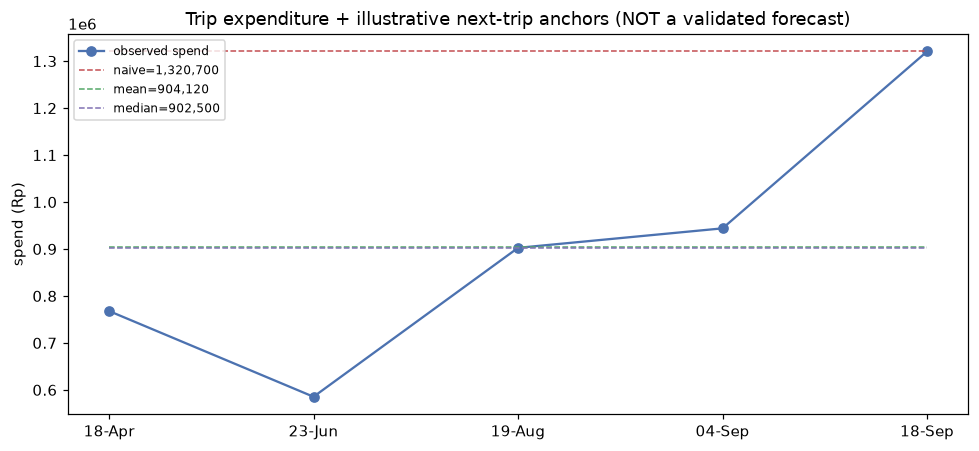

In [23]:
# 7.5 Visual: observed trip spend + the three illustrative anchors for the next trip.
fig, ax = plt.subplots(figsize=(9,4.2))
ax.plot(trip.index.strftime('%d-%b'), ts.values, marker="o", color="#4C72B0", label="observed spend")
nx = len(ts)
for val, lab, c in [(naive_next,"naive","#C44E52"),(mean_next,"mean","#55A868"),(median_next,"median","#8172B3")]:
    ax.hlines(val, xmin=0, xmax=nx-1, color=c, ls="--", lw=1, label=f"{lab}={val:,.0f}")
ax.set_title("Trip expenditure + illustrative next-trip anchors (NOT a validated forecast)")
ax.set_ylabel("spend (Rp)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 8. Scenario & Sensitivity Analysis

All scenarios below are **hypothetical** and labelled as such. They recompute expenditure
under stated assumptions using **observed historical prices**. They are **not predictions**
of future conditions. Each scenario states its assumptions explicitly.

In [24]:
# Baseline = total observed restock spend (rupiah-normalised).
baseline_spend = df["line_spend_rp"].sum()
print(f"Baseline observed total restock spend: {baseline_spend:,.0f} Rp")

scenarios = {}

# Scenario A: +5% price on the 10 highest-spend ('A') products, quantities unchanged.
topA = prod.sort_values("spend", ascending=False).head(10).index
addA = df.loc[df["item_name"].isin(topA), "line_spend_rp"].sum() * 0.05
scenarios["A: +5% price on top-10 spend products"] = baseline_spend + addA

# Scenario B: +10% planned quantities across ALL items, prices unchanged.
scenarios["B: +10% quantity on all items"] = baseline_spend * 1.10

# Scenario C: +15% cost on the single highest-expenditure brand.
top_brand = df.groupby("brand")["line_spend_rp"].sum().idxmax()
addC = df.loc[df["brand"]==top_brand, "line_spend_rp"].sum() * 0.15
scenarios[f"C: +15% cost on top brand ({top_brand})"] = baseline_spend + addC

scen_df = pd.DataFrame({"scenario": list(scenarios), "total_spend_rp": list(scenarios.values())})
scen_df["delta_vs_baseline"] = scen_df["total_spend_rp"] - baseline_spend
scen_df["delta_pct"] = (scen_df["delta_vs_baseline"]/baseline_spend*100).round(1)
scen_df["total_spend_rp"] = scen_df["total_spend_rp"].round(0)
scen_df

Baseline observed total restock spend: 4,520,600 Rp


,scenario,total_spend_rp,delta_vs_baseline,delta_pct
0,A: +5% price on top-10 spend products,4627830.0,107230.0,2.4
1,B: +10% quantity on all items,4972660.0,452060.0,10.0
2,C: +15% cost on top brand (MILKU),4591625.0,71025.0,1.6


In [25]:
# Scenario D: BUDGET-CONSTRAINED trip. Assumption: a fixed budget; buy A-class products
# first (highest spend contribution), using each product's MEDIAN observed unit price and
# its MEDIAN observed qty, until the budget runs out. Purely illustrative prioritisation.
BUDGET = 800_000  # hypothetical Rp budget for one trip

plan = prod.copy()
plan["median_price"] = df.groupby("item_name")["unit_price_rp"].median()
plan["median_qty"] = df.groupby("item_name")["qty"].median()
plan["line_cost"] = plan["median_price"] * plan["median_qty"]
plan = plan.sort_values("spend", ascending=False)  # priority = historical spend contribution
plan["cum_cost"] = plan["line_cost"].cumsum()
chosen = plan[plan["cum_cost"] <= BUDGET]
print(f"Scenario D (hypothetical): with a {BUDGET:,.0f} Rp budget, prioritising by historical")
print(f"spend and using median price*median qty, ~{len(chosen)} of {len(plan)} products fit.")
print(f"Planned spend: {chosen['line_cost'].sum():,.0f} Rp  (leftover {BUDGET-chosen['line_cost'].sum():,.0f})")
chosen[["spend","median_price","median_qty","line_cost","cum_cost"]].head(12)

Scenario D (hypothetical): with a 800,000 Rp budget, prioritising by historical
spend and using median price*median qty, ~15 of 90 products fit.
Planned spend: 790,800 Rp  (leftover 9,200)


,spend,median_price,median_qty,line_cost,cum_cost
item_name,,,,,
PUCUK HARUM TEH MELATI 350ml,369000.0,71100.0,1.5,106650.0,106650.0
MILKU SUSU STRO 200,300200.0,34700.0,1.0,34700.0,141350.0
SPRITE PET 390 ML,292100.0,56500.0,1.0,56500.0,197850.0
N/P MINUMAN LIME 330,238000.0,47600.0,2.0,95200.0,293050.0
ISOPLUS BTL 350ML,207800.0,30000.0,1.0,30000.0,323050.0
COCA COLA PET 390 ML,175000.0,56500.0,1.0,56500.0,379550.0
MILKU SUSU CKLT 200,173300.0,34700.0,1.0,34700.0,414250.0
VIT AIR MINERAL 550,158700.0,31900.0,2.0,63800.0,478050.0
FANTA STRW PET 390ML,117100.0,58550.0,1.0,58550.0,536600.0


In [26]:
# Scenario E: FIXED BASKET at different trips' prices (true price comparison).
# Assumption: a fixed basket of products that appear on BOTH the first and last trip,
# quantity = 1 each, priced at that trip's observed unit price. Equivalent products only.
d0, d1 = df["receipt_date"].min(), df["receipt_date"].max()
p0 = df[df["receipt_date"]==d0].groupby("item_name")["unit_price_rp"].mean()
p1 = df[df["receipt_date"]==d1].groupby("item_name")["unit_price_rp"].mean()
common = p0.index.intersection(p1.index)
basket = pd.DataFrame({f"price_{d0.date()}": p0[common], f"price_{d1.date()}": p1[common]})
basket["diff"] = basket.iloc[:,1] - basket.iloc[:,0]
print(f"Fixed basket of {len(common)} products common to {d0.date()} and {d1.date()} (qty=1 each):")
print(f"  cost at {d0.date()} prices: {basket.iloc[:,0].sum():,.0f} Rp")
print(f"  cost at {d1.date()} prices: {basket.iloc[:,1].sum():,.0f} Rp")
print(f"  difference: {basket['diff'].sum():,.0f} Rp (positive = more expensive later)")
print("  Assumption: identical products & packaging, qty 1 each. NOT a claim of real savings.")
basket

Fixed basket of 13 products common to 2026-04-18 and 2026-09-18 (qty=1 each):
  cost at 2026-04-18 prices: 370,300 Rp
  cost at 2026-09-18 prices: 376,100 Rp
  difference: 5,800 Rp (positive = more expensive later)
  Assumption: identical products & packaging, qty 1 each. NOT a claim of real savings.


,price_2026-04-18,price_2026-09-18,diff
item_name,,,
BONCABE MAKARONI LEVEL 15 27G,17200.0,17200.0,0.0
GOLDA CAPPUCCINO 200,37300.0,37300.0,0.0
GOLDA COFF.DOLCE 200,37300.0,37300.0,0.0
ISOPLUS BTL 350ML,28900.0,30000.0,1100.0
ISOPLUS COCO 350ML,28900.0,30000.0,1100.0
MILKU SUSU CKLT 200,34500.0,34700.0,200.0
MILKU SUSU STRO 200,34500.0,34700.0,200.0
OISHI POPCORN CARAMEL 20G,17500.0,17500.0,0.0
OISHI POPCORN KEJU 20G,17500.0,17500.0,0.0


In [27]:
# Sensitivity: how much do the two flagged anomalies move the headline totals?
anom_names = ["ISOPLUS COCO 350ML","PUCUK HARUM TEH MELATI 350ml"]
anom_rows = df[(df["item_name"].isin(anom_names)) &
               ((df["unit_price_rp"] < df.groupby("item_name")["unit_price_rp"].transform("median")*0.2))]
df_excl = df.drop(index=anom_rows.index)
comp = pd.DataFrame({
    "metric": ["total spend (Rp)","total units"],
    "with_all_records": [df["line_spend_rp"].sum(), df["qty"].sum()],
    "excluding_flagged": [df_excl["line_spend_rp"].sum(), df_excl["qty"].sum()],
})
comp["abs_change"] = comp["excluding_flagged"] - comp["with_all_records"]
comp["pct_change"] = (comp["abs_change"]/comp["with_all_records"]*100).round(2)
print("SENSITIVITY (clearly labelled): headline metrics with vs without the flagged rows.")
print("We do NOT delete these rows from the dataset - this only measures their influence.")
display(comp)
print("Flagged rows considered:")
display(anom_rows[["source_sheet","item_name","qty","unit_price_rp","line_spend_rp"]])

SENSITIVITY (clearly labelled): headline metrics with vs without the flagged rows.
We do NOT delete these rows from the dataset - this only measures their influence.


,metric,with_all_records,excluding_flagged,abs_change,pct_change
0,total spend (Rp),4520600.0,4442500.0,-78100.0,-1.73
1,total units,396.0,371.0,-25.0,-6.31


Flagged rows considered:


,source_sheet,item_name,qty,unit_price_rp,line_spend_rp
75,struk belanja (19-08-2026),ISOPLUS COCO 350ML,1.0,2500.0,2500.0
152,struk belanja (18-09-2026),PUCUK HARUM TEH MELATI 350ml,24.0,3150.0,75600.0


## 9. Inventory Planning Framework

Proper reorder points and safety stock need **consumption rate, lead time, and on-hand
stock** - none of which exist in restock receipts. So we do **not** compute reorder points.
Instead we build a **priority-monitoring framework** from what *is* available, and specify
the fields required to complete it.

| Planning output | Needs | Available now? |
|---|---|---|
| Priority watch-list | spend + purchase frequency | **Yes** (below) |
| Reorder point | avg demand/day x lead time | No - needs sales + lead time |
| Safety stock | demand variability + service level | No - needs sales history |
| Economic order qty | order cost + holding cost | No - needs cost structure |

In [28]:
# Priority watch-list we CAN build: frequently bought AND high spend = monitor closely.
watchlist = prod.copy()
# normalise two signals to 0-1 and combine into a simple priority score (transparent rule).
watchlist["freq_score"]  = watchlist["trips"] / watchlist["trips"].max()
watchlist["spend_score"] = watchlist["spend"] / watchlist["spend"].max()
watchlist["priority_score"] = (0.5*watchlist["freq_score"] + 0.5*watchlist["spend_score"]).round(3)
watchlist = watchlist.sort_values("priority_score", ascending=False)
print("Top 15 products to MONITOR (priority = 50% purchase-frequency + 50% spend share):")
watchlist.head(15)[["spend","trips","records","qty","priority_score","ABC"]]

Top 15 products to MONITOR (priority = 50% purchase-frequency + 50% spend share):


,spend,trips,records,qty,priority_score,ABC
item_name,,,,,,
MILKU SUSU STRO 200,300200.0,5,5,8.0,0.907,A
PUCUK HARUM TEH MELATI 350ml,369000.0,4,4,28.0,0.900,A
SPRITE PET 390 ML,292100.0,5,5,5.0,0.896,A
ISOPLUS BTL 350ML,207800.0,5,5,7.0,0.782,A
MILKU SUSU CKLT 200,173300.0,4,4,5.0,0.635,A
N/P MINUMAN LIME 330,238000.0,3,3,5.0,0.622,A
COCA COLA PET 390 ML,175000.0,3,3,3.0,0.537,A
ISOPLUS COCO 350ML,90300.0,4,4,4.0,0.522,A
OISHI POPCORN KEJU 20G,87500.0,4,4,5.0,0.519,A


In [29]:
# Framework output: what each product needs next to become fully plannable.
print("To convert this watch-list into real reorder policy, collect per product:")
for f in ["daily/weekly units SOLD","current on-hand stock","supplier lead time (days)",
          "pack-to-piece conversion (use 'isi')","stockout dates"]:
    print("  -", f)

To convert this watch-list into real reorder policy, collect per product:
  - daily/weekly units SOLD
  - current on-hand stock
  - supplier lead time (days)
  - pack-to-piece conversion (use 'isi')
  - stockout dates


## 10. Product & Brand Segmentation

Interpretable, rule-based segments (no clustering needed at this size). We segment on
**expenditure contribution** (ABC) x **purchase frequency** (recurring vs occasional), and
flag **price stability**. We deliberately avoid labels like *bestseller* / *fast-moving* -
those require sales data we do not have.

In [30]:
# Priority matrix: ABC (spend) x recurrence (purchase frequency).
seg = prod.copy()
seg["recurrence"] = np.where(seg["trips"]>=3, "recurring (>=3 trips)",
                      np.where(seg["trips"]==2, "occasional (2 trips)", "one-off (1 trip)"))
matrix = pd.crosstab(seg["ABC"], seg["recurrence"])
print("Product-priority matrix: count of products in each ABC x recurrence cell")
display(matrix)

# price stability tag (from section 6 stats, defaulting single-obs products to 'n/a')
pstats_all = df.groupby("item_name")["unit_price_rp"].agg(n="count", rng=lambda s: s.max()-s.min())
seg["price_tag"] = np.where(pstats_all["n"]<2, "single obs",
                     np.where(pstats_all["rng"]==0, "stable", "variable"))
print("\nA-class, recurring products = the core purchasing backbone to watch:")
display(seg[(seg["ABC"]=="A") & (seg["trips"]>=3)]
        [["spend","trips","qty","price_tag"]].sort_values("spend", ascending=False))

Product-priority matrix: count of products in each ABC x recurrence cell


recurrence,occasional (2 trips),one-off (1 trip),recurring (>=3 trips)
ABC,,,
A,11,3,20
B,9,18,3
C,1,25,0



A-class, recurring products = the core purchasing backbone to watch:


,spend,trips,qty,price_tag
item_name,,,,
PUCUK HARUM TEH MELATI 350ml,369000.0,4,28.0,stable
MILKU SUSU STRO 200,300200.0,5,8.0,variable
SPRITE PET 390 ML,292100.0,5,5.0,variable
N/P MINUMAN LIME 330,238000.0,3,5.0,variable
ISOPLUS BTL 350ML,207800.0,5,7.0,variable
COCA COLA PET 390 ML,175000.0,3,3.0,variable
MILKU SUSU CKLT 200,173300.0,4,5.0,variable
VIT AIR MINERAL 550,158700.0,3,5.0,single obs
ISOPLUS COCO 350ML,90300.0,4,4.0,single obs


In [31]:
# Brand-level mix: spend, distinct products, units. Brand = first token (heuristic).
brand = (df.groupby("brand")
           .agg(spend=("line_spend_rp","sum"), products=("item_name","nunique"),
                units=("qty","sum"), records=("item_name","size"))
           .sort_values("spend", ascending=False))
brand["spend_pct"] = (brand["spend"]/brand["spend"].sum()*100).round(1)
print("Top 12 brands by spend (brand extraction is heuristic - treat coded names with care):")
brand.head(12)

Top 12 brands by spend (brand extraction is heuristic - treat coded names with care):


,spend,products,units,records,spend_pct
brand,,,,,
MILKU,473500.0,2,13.0,9,10.5
PUCUK,369000.0,1,28.0,4,8.2
AOKA,305200.0,7,165.0,19,6.8
ISOPLUS,298100.0,2,11.0,9,6.6
SPRITE,292100.0,1,5.0,5,6.5
OKKY,254400.0,6,11.0,10,5.6
N/P,238000.0,1,5.0,3,5.3
OISHI,229200.0,4,13.0,10,5.1
COCA,175000.0,1,3.0,3,3.9


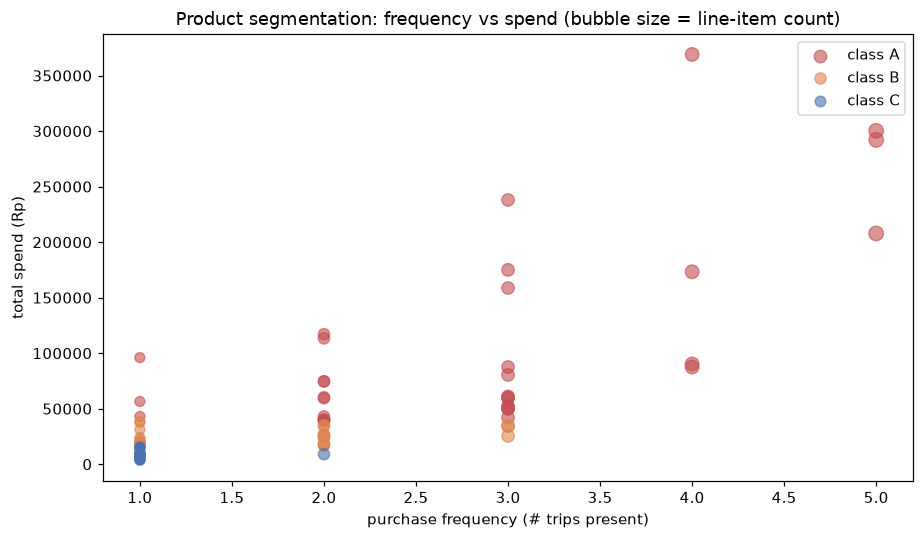

In [32]:
# Segmentation viz: scatter of purchase frequency vs spend, coloured by ABC.
fig, ax = plt.subplots(figsize=(8.5,5))
colors = {"A":"#C44E52","B":"#DD8452","C":"#4C72B0"}
for cls, g in seg.groupby("ABC"):
    ax.scatter(g["trips"], g["spend"], s=30+g["records"]*12, alpha=0.6,
               color=colors.get(cls,"grey"), label=f"class {cls}")
ax.set_xlabel("purchase frequency (# trips present)")
ax.set_ylabel("total spend (Rp)")
ax.set_title("Product segmentation: frequency vs spend (bubble size = line-item count)")
ax.legend(); plt.tight_layout(); plt.show()

### 10.1 Advanced methods - feasibility check (why we stop here)

| Method | Enough data? | Verdict |
|---|---|---|
| **Clustering** products by restock pattern | 90 products but only 5 trip-features, dominated by 'present once' | Weak - segments above are clearer and interpretable |
| **Association / market-basket** | only **5 baskets** (trips) | **Not viable** - needs hundreds of baskets |
| **Outlier detection** | useful, and already done via rule-based flags (section 3) | Done pragmatically |
| **Price-stability ranking** | yes (section 6) | **Done** |
| **Assortment similarity** across trips | yes (Jaccard below) | Light, meaningful |

We do not run clustering or association mining: at this sample size they would be
statistically hollow. The interpretable segments and the assortment-similarity check below
answer the same business questions more honestly.

In [33]:
# Assortment similarity between trips (Jaccard overlap of product sets). Meaningful & simple.
sets = {d.date(): set(g["item_name"]) for d, g in df.groupby("receipt_date")}
ds = sorted(sets)
J = pd.DataFrame(index=ds, columns=ds, dtype=float)
for a in ds:
    for b in ds:
        inter = len(sets[a] & sets[b]); union = len(sets[a] | sets[b])
        J.loc[a,b] = round(inter/union, 2) if union else np.nan
print("Jaccard similarity of product assortment between trips (1 = identical baskets):")
display(J)
print("Low values => assortment changes a lot trip-to-trip, consistent with ad-hoc restocking.")

Jaccard similarity of product assortment between trips (1 = identical baskets):


,2026-04-18,2026-06-23,2026-08-19,2026-09-04,2026-09-18
2026-04-18,1.00,0.26,0.27,0.08,0.21
2026-06-23,0.26,1.00,0.17,0.11,0.24
2026-08-19,0.27,0.17,1.00,0.25,0.33
2026-09-04,0.08,0.11,0.25,1.00,0.33
2026-09-18,0.21,0.24,0.33,0.33,1.00


Low values => assortment changes a lot trip-to-trip, consistent with ad-hoc restocking.


## 11. Key Findings, Recommendations, Limitations & Data Plan

### 11.1 Evidence-based insights (each traceable to a cell above)
1. **Spending is concentrated.** ~35 of 90 products (~39%) make up ~80% of spend; the ABC
   split is A=34 (~79% spend), B=30 (~16%), C=26 (~5%). *(Section 4)*
2. **Frequency != quantity != spend.** The most *frequently bought* items (SPRITE, MILKU,
   ISOPLUS drinks) differ from the highest-*quantity* items (AOKA breads) and from the
   highest-*spend* items (PUCUK HARUM tea, MILKU, drinks). *(Section 4)*
3. **Only three products were bought on all five trips** (MILKU SUSU STRO 200, SPRITE PET
   390 ML, ISOPLUS BTL 350ML); 46 products appear only once. Restocking is largely ad-hoc.
   *(Section 5)*
4. **Trip spend tracks units & assortment**, not average price - the biggest trip (18-Sep)
   had the most units and items. This is an observed association across 5 trips, not proven
   cause. *(Section 5)*
5. **Most prices are stable; a few drinks drift.** 24 products show an identical price every
   trip; SPRITE/COCA COLA move within ~56.5k-62k. Two records (ISOPLUS COCO, PUCUK HARUM)
   are data anomalies, not real price moves. *(Sections 3, 6)*
6. **Assortment overlap between trips is low** (Jaccard), confirming purchasing is driven by
   restock timing/availability rather than a fixed recurring list. *(Section 10.1)*
7. **The flagged anomalies materially move totals** if trusted: excluding them changes spend
   and units by the amounts shown in the section-8 sensitivity table - so they must be
   confirmed before any budgeting. *(Section 8)*

### 11.2 Ranked products to MONITOR (purchasing priority, not sales importance)
Top of the section-9 watch-list (50% purchase-frequency + 50% spend share): the recurring,
high-spend drinks - **MILKU SUSU STRO 200, SPRITE PET 390 ML, ISOPLUS BTL 350ML**, then
**PUCUK HARUM TEH MELATI, MILKU SUSU CKLT 200, N/P MINUMAN LIME, COCA COLA**. See the
`watchlist` table for the full ranked list and scores.

### 11.3 Forecasting verdict
**Product-level demand forecasting is not defensible** (only 7 products with >=4 obs; no
sales data). **Trip-level expenditure** has 5 points; baseline errors (section 7.3) are a
large share of the mean, so even the aggregate figure is a **planning anchor, not a
forecast**. Use the illustrative range (~585k-1.32m, mean ~904k Rp/trip) only for rough
budgeting, with the stated warning.

### 11.4 Three to five actionable recommendations
1. **Lock in the recurring staples.** Keep the always-bought drinks on a standing buy-list
   with a target quantity, so they are never the reason for an emergency trip.
2. **Buy price-stable items in planned bulk; time the variable drinks.** For SPRITE/COCA
   COLA, buy on the cheaper trips you observe; for the 24 stable items, budget with
   confidence.
3. **Confirm the two flagged records** (ISOPLUS COCO price, PUCUK HARUM qty/price) before
   using any total for budgeting - section 8 shows they shift the headline numbers.
4. **Standardise data capture** (one date format, one money scale, record packaging units)
   so the next five trips are directly comparable.
5. **Start logging sales/consumption** (section 11.6) - it is the single change that unlocks
   real demand forecasting and reorder points.

### 11.5 Limitations & unresolved data-quality issues
- Restock-only data: **no sales, consumption, revenue, profit, or stock levels**.
- **5 irregular trips** over ~5 months: too few and too uneven for reliable time-series work.
- **Mixed packaging**: `qty` sums pieces and cartons; "total units" is indicative only.
- **Mixed monetary scale** handled via a derived `unit_price_rp`; raw columns preserved.
- **Two transcription anomalies** remain flagged (not corrected).
- **Brand = first name token** is heuristic; coded names (N/P, S/N, BC) are approximate.

### 11.6 Data-collection plan to enable real forecasting
To move from *restock analysis* to *demand forecasting & inventory control*, capture:
1. **Daily/weekly units sold per product** (the core demand signal).
2. **Selling price & sales revenue** per product.
3. **Opening & closing inventory** each period.
4. **Stockout periods / unavailable products** (so zeros mean true zero demand).
5. **Packaging conversion factors** (pieces per carton - partly in `isi`).
6. **Supplier lead times** and **purchase vs delivery dates**.
7. **Expiry / spoilage records** for perishables (e.g. AOKA bread).
8. **Consistent purchase cost & discounts** in one scale and date format.

With (1)-(4) alone, Kaftet could compute consumption rates, reorder points and safety stock,
and validate forecasts properly with chronological backtesting.

### 11.7 Conclusion
After extended analysis, the dataset reliably answers **purchasing** questions - what was
bought, how often, in what quantity, at what cost, and how concentrated and price-stable that
spending is. It does **not** support demand forecasting or claims about what sells. The
honest path forward is to keep the clean purchasing pipeline, monitor the ranked high-spend
recurring items, confirm the flagged anomalies, and begin collecting sales & inventory data -
at which point the forecasting and reorder sections here can be upgraded from *illustrative*
to *operational*.